## 1. BUSINESS UNDERSTANDING

### 1.1 Project background

Flooding is a recurring urban risk in Nairobi. Heavy rainfall, terrain characteristics, drainage conditions, land cover and patterns of urban development can contribute to where water accumulates and where flooding may occur.

Flood events can disrupt transport, damage homes and businesses, affect essential services and put lives at risk. Identifying locations that may be more susceptible to flooding can help urban planners, disaster-response teams and other stakeholders prioritise further investigation and risk-reduction activities.

This capstone project uses geographic point data and machine-learning techniques to investigate patterns associated with recorded flood locations in Nairobi and develop a preliminary flood-susceptibility mapping tool.

### 1.2 Problem statement

Nairobi experiences flooding in different locations, but decision-makers need accessible, location-based information to help identify areas that may be more susceptible. Without a consistent way to analyse terrain, land-cover, built-up characteristics and proximity to mapped water features together, it can be difficult to compare locations and prioritise areas for further assessment.

The project therefore seeks to use historical/sample flood labels and geographic characteristics to train and evaluate machine-learning models that estimate the relative flood susceptibility of locations in the study area. The resulting predictions will be presented on a map through an interactive application.

**Important:** The model will estimate susceptibility from the available dataset. It will not provide real-time flood warnings, predict the exact timing or depth of a flood, or guarantee that a location is safe.

## 2. DATA UNDERSTANDING

### 2.1 Dataset Loading


#### 2.1.1 Import Required Libraries

This section imports the Python libraries required for data loading, manipulation, numerical analysis and visualization.

- **Pandas:** Used to load, inspect and manipulate the dataset.
- **NumPy:** Supports numerical operations and data analysis.
- **Matplotlib:** Used to create graphs and visualize patterns in the dataset.
- **Seaborn:** Provides additional statistical visualization capabilities.

These libraries will support the data understanding and preparation stages of the project.


In [3]:
# Import libraries
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)



#### 2.1.2 Load the Flood Susceptibility Dataset

The project dataset is loaded into a Pandas DataFrame named **df**.

The dataset contains geographic sample points, their associated environmental and terrain characteristics, and a binary flood label.

Each row represents a sampled geographic location, while the columns describe its characteristics and recorded flood status.

This dataset will be used to explore relationships between geographic features and flood occurrence before preparing the data for machine learning.


In [4]:
# Load the dataset
df = pd.read_csv("points_features complete.csv")

### 2.2 Initial Dataset Inspection


#### 2.2.1 Dataset Structure and Data Types

The dataset information is examined to understand the structure and data types of each column.

This inspection helps identify:

- The number of non-null values in each column.
- The data type assigned to each variable.
- Columns that may require data type conversion.
- Variables that contain missing observations.

Understanding the data types is important because numerical, categorical and identification variables require different treatment during data preparation and modelling.


In [5]:
df.head()

,point_id,lon,lat,flooded,elevation,slope,local_relief_100,local_relief_500,concavity,land_cover,builtup_100,builtup_500,dist_river,dist_stream,dist_drain,block_id
0,1,37.054329,-1.299028,0,1497.815308,0.643400,0.784040,0.919611,-0.242782,40,0.009070,0.076953,343.582858,343.582858,11410.265778,283_9856
1,2,37.051868,-1.297120,1,1491.494019,1.070903,-0.562037,-3.348700,0.486544,30,0.000000,0.098520,8.770712,8.770712,11157.685323,283_9856
2,3,36.979077,-1.223612,1,1503.143555,0.114747,-0.132010,-1.802306,0.111572,30,0.034014,0.235663,93.445852,93.445852,3906.903944,275_9864
3,4,37.086873,-1.232403,1,1486.456299,0.068787,-0.188992,-0.402524,0.026636,30,0.000000,0.003921,2807.757821,2807.757821,14690.733996,287_9863
4,5,37.068898,-1.188922,0,1480.674805,0.426800,-0.134649,0.193810,0.016965,30,0.000000,0.000000,1369.394675,1369.394675,14274.306088,285_9868


In [6]:
# Rows and Columns
df.shape

(19878, 16)

In [7]:
# Columns names
df.columns.tolist()

['point_id',
 'lon',
 'lat',
 'flooded',
 'elevation',
 'slope',
 'local_relief_100',
 'local_relief_500',
 'concavity',
 'land_cover',
 'builtup_100',
 'builtup_500',
 'dist_river',
 'dist_stream',
 'dist_drain',
 'block_id']

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19878 entries, 0 to 19877
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   point_id          19878 non-null  int64  
 1   lon               19878 non-null  float64
 2   lat               19878 non-null  float64
 3   flooded           19878 non-null  int64  
 4   elevation         19878 non-null  float64
 5   slope             19878 non-null  float64
 6   local_relief_100  19878 non-null  float64
 7   local_relief_500  19878 non-null  float64
 8   concavity         19878 non-null  float64
 9   land_cover        19878 non-null  int64  
 10  builtup_100       19878 non-null  float64
 11  builtup_500       19878 non-null  float64
 12  dist_river        19878 non-null  float64
 13  dist_stream       19878 non-null  float64
 14  dist_drain        19878 non-null  float64
 15  block_id          19878 non-null  object 
dtypes: float64(12), int64(3), object(1)
memo

In [9]:
df.sample(5, random_state=42)


,point_id,lon,lat,flooded,elevation,slope,local_relief_100,local_relief_500,concavity,land_cover,builtup_100,builtup_500,dist_river,dist_stream,dist_drain,block_id
9387,9445,37.071404,-1.241612,1,1488.868164,0.095988,0.269965,0.314444,-0.144754,30,0.000000,0.000000,3856.308633,3856.308633,12870.647622,285_9862
19731,19854,37.061292,-1.199785,1,1475.354858,0.475881,-0.302630,-0.712621,0.139382,30,0.000000,0.000000,667.554773,667.554773,12974.483923,284_9867
18736,18854,36.874847,-1.252687,1,1599.356567,4.281172,-0.972748,-9.502680,0.709131,50,0.870748,0.926870,12.044938,12.044938,1353.515085,263_9861
4420,4446,36.988244,-1.259234,0,1517.871216,1.889360,0.284658,4.481194,-0.127690,50,0.580499,0.533477,1284.605645,1284.605645,3710.964984,276_9860
1692,1699,36.996982,-1.206981,1,1493.609253,0.697952,-0.073805,-0.039736,0.063731,30,0.000000,0.011567,224.816690,224.816690,6609.080561,277_9866



#### 2.2.2 Checking for Duplicate Records

Duplicate records are identified to determine whether identical rows occur more than once in the dataset.

Duplicate observations can introduce unnecessary repetition and may affect the reliability of subsequent analysis and model evaluation.

The result will help determine whether duplicate records need to be removed during data preparation.


In [10]:
df.duplicated().sum()


np.int64(0)


#### 2.2.3 Checking for Missing Values

The total number of missing values across the dataset is calculated.

Missing values are important to identify because incomplete observations can affect statistical analysis and machine-learning algorithms.

This initial check establishes whether missing data is present. A column-level inspection will also be necessary if missing values are identified so that appropriate treatment decisions can be made during data preparation.


In [11]:
df.isna().sum().sum()

np.int64(0)


### 2.3 Initial Data Dictionary

A data dictionary is created to document the meaning and intended project use of each original dataset column.

The dictionary contains three main descriptions:

- **Column name:** Identifies the variable in the dataset.
- **Working description:** Explains what the variable represents.
- **Planned project use:** Describes whether the variable will serve as a predictor, target, metadata or excluded feature.

This documentation helps maintain a clear understanding of the dataset and supports consistent feature selection during the modelling stage.

The data dictionary is also exported as **project_data_dictionary.csv** for reference by other project members.

**Note:** The working descriptions and units should be confirmed against the original dataset documentation where available.


In [12]:
data_dictionary = pd.DataFrame([
    ["point_id", "Unique identifier for a sampled point", "Identifier; not a model predictor"],
    ["lon", "Longitude coordinate", "Retain for mapping; exclude as predictor by default"],
    ["lat", "Latitude coordinate", "Retain for mapping; exclude as predictor by default"],
    ["flooded", "Binary flood label: 1 or 0", "Target variable to predict"],
    ["elevation", "Ground elevation at the point", "Candidate terrain predictor; confirm units"],
    ["slope", "Terrain slope at the point", "Candidate terrain predictor; confirm units"],
    ["local_relief_100", "Local terrain relief over a 100-unit neighbourhood", "Candidate terrain predictor; confirm neighbourhood and units"],
    ["local_relief_500", "Local terrain relief over a 500-unit neighbourhood", "Candidate terrain predictor; confirm neighbourhood and units"],
    ["concavity", "Terrain concavity or landform-shape measure", "Candidate terrain predictor; confirm calculation"],
    ["land_cover", "Land-cover classification code", "Categorical predictor; confirm class legend"],
    ["builtup_100", "Built-up measure within a 100-unit neighbourhood", "Candidate predictor; confirm scale and units"],
    ["builtup_500", "Built-up measure within a 500-unit neighbourhood", "Candidate predictor; confirm scale and units"],
    ["dist_river", "Distance to mapped river feature", "Candidate predictor; confirm units and source"],
    ["dist_stream", "Distance to mapped stream feature", "Candidate predictor; compare with dist_river"],
    ["dist_drain", "Distance to mapped drainage feature", "Excluded according to current project plan"],
    ["block_id", "Identifier for a spatial block", "Retain for spatial splitting; not a model predictor"]
], columns=["column_name", "working_description", "planned_project_use"])

display(data_dictionary)
data_dictionary.to_csv("project_data_dictionary.csv", index=False)
print("project_data_dictionary.csv")


,column_name,working_description,planned_project_use
0,point_id,Unique identifier for a sampled point,Identifier; not a model predictor
1,lon,Longitude coordinate,Retain for mapping; exclude as predictor by default
2,lat,Latitude coordinate,Retain for mapping; exclude as predictor by default
3,flooded,Binary flood label: 1 or 0,Target variable to predict
4,elevation,Ground elevation at the point,Candidate terrain predictor; confirm units
5,slope,Terrain slope at the point,Candidate terrain predictor; confirm units
6,local_relief_100,Local terrain relief over a 100-unit neighbourhood,Candidate terrain predictor; confirm neighbourhood and units
7,local_relief_500,Local terrain relief over a 500-unit neighbourhood,Candidate terrain predictor; confirm neighbourhood and units
8,concavity,Terrain concavity or landform-shape measure,Candidate terrain predictor; confirm calculation
9,land_cover,Land-cover classification code,Categorical predictor; confirm class legend


project_data_dictionary.csv


### 2.4 Exploratory Data Analysis (EDA)

#### 2.4.1 Understanding the Target Variable

The target variable for this project is **flooded**.

This analysis examines the number and percentage of observations belonging to each target class.

It also checks for unexpected values outside the expected binary labels of 0 and 1.

Understanding the target distribution is important because it helps determine whether the dataset contains a balanced representation of flooded and non-flooded locations.

This information will guide later modelling decisions, particularly the choice of evaluation metrics and the handling of potential class imbalance.

In [13]:
print("Target label counts:")
display(df["flooded"].value_counts(dropna=False).sort_index())

print("\nTarget label percentages:")
display((df["flooded"].value_counts(normalize=True, dropna=False) * 100).round(2))

print("\nUnexpected target values:")
display(df.loc[~df["flooded"].isin([0, 1]), "flooded"].value_counts())

Target label counts:


flooded
0    9907
1    9971
Name: count, dtype: int64


Target label percentages:


flooded
1    50.16
0    49.84
Name: proportion, dtype: float64


Unexpected target values:


Series([], Name: count, dtype: int64)

#### 2.4.1.1 Visualising Flood Label Distribution

A bar chart is generated to visually compare the number of observations in the two target classes.

The chart displays:

- Class 0: Locations labelled as not flooded.
- Class 1: Locations labelled as flooded.

Visualising the target distribution makes it easier to identify whether one class is more represented than the other.

This is important because a significant imbalance between the classes may influence model training and evaluation.

The distribution will help inform the selection of appropriate evaluation metrics beyond accuracy alone.


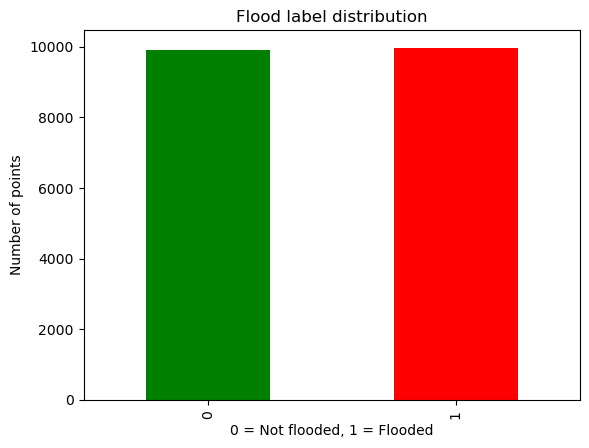

In [14]:
df["flooded"].value_counts().sort_index().plot(kind="bar", color=["green", "red"])
plt.title("Flood label distribution")
plt.xlabel("0 = Not flooded, 1 = Flooded")
plt.ylabel("Number of points")
plt.show()

#### 2.4.2 Descriptive Statistics
Descriptive statistics are generated to summarise the numerical variables in the dataset.

The summary includes:

- **Count:** Number of available observations.
- **Mean:** Average value.
- **Standard deviation:** Measures the spread of values.
- **Minimum:** Lowest recorded value.
- **25%:** First quartile.
- **50%:** Median value.
- **75%:** Third quartile.
- **Maximum:** Highest recorded value.

This analysis helps us understand the distribution, range and variability of the numerical features.

It also helps identify unusually large or small values that may require further investigation before modelling.


In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
point_id,19878.0,9999.263105,5775.130493,1.000000,4999.250000,10000.500000,15000.750000,20000.000000
lon,19878.0,37.005080,0.064685,36.839195,36.958303,37.016174,37.060580,37.099993
lat,19878.0,-1.236748,0.042658,-1.322505,-1.270818,-1.233550,-1.207094,-1.150003
flooded,19878.0,0.501610,0.500010,0.000000,0.000000,1.000000,1.000000,1.000000
elevation,19878.0,1514.027581,48.175153,1442.777466,1483.570923,1493.473511,1531.087830,1671.097168
slope,19878.0,1.455381,2.070879,0.000000,0.359421,0.720067,1.658999,30.989304
local_relief_100,19878.0,-0.196670,1.336403,-19.228974,-0.346517,-0.042193,0.189490,11.901900
local_relief_500,19878.0,-1.156090,4.579180,-32.425903,-1.624908,-0.197344,0.536788,20.215658
concavity,19878.0,0.104250,0.680271,-5.451727,-0.082946,0.018696,0.163896,10.207410
land_cover,19878.0,33.680954,11.270288,10.000000,30.000000,30.000000,40.000000,90.000000


#### 2.4.3 Univariate Analysis

In [16]:
# Univariate Statistical Summary 
# 1. Select numeric features (elevation, slope, concavity, distances)
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop('land_cover', errors='ignore')

# 2. Comprehensive statistical summary with extended percentiles
univ_summary = df[numeric_cols].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T

# 3. Add Skewness to detect heavily right-skewed water distances or elevation tails
univ_summary['skewness'] = df[numeric_cols].skew()

# 4. Calculate outlier percentages using the IQR method
outlier_percentages = {}
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_percentages[col] = (len(outliers) / len(df)) * 100

univ_summary['outlier_pct'] = pd.Series(outlier_percentages)

#  Univariate summary table
display(univ_summary[['mean', 'std', '50%', 'skewness', 'outlier_pct']].rename(columns={'50%': 'median'}))

,mean,std,median,skewness,outlier_pct
point_id,9999.263105,5775.130493,10000.500000,0.000023,0.000000
lon,37.005080,0.064685,37.016174,-0.576523,0.000000
lat,-1.236748,0.042658,-1.233550,-0.096425,0.000000
flooded,0.501610,0.500010,1.000000,-0.006440,0.000000
elevation,1514.027581,48.175153,1493.473511,1.234472,9.518060
slope,1.455381,2.070879,0.720067,3.813358,9.513029
local_relief_100,-0.196670,1.336403,-0.042193,-2.332572,16.727035
local_relief_500,-1.156090,4.579180,-0.197344,-1.831231,19.026059
concavity,0.104250,0.680271,0.018696,2.599753,17.743234
builtup_100,0.204720,0.321463,0.006803,1.412453,10.725425


####  Key Insights: Univariate Statistical Summary

* **Balanced Target (`flooded):** With a mean of **0.502** (50.2% flooded vs. 49.8% non-flooded), the target classes are evenly balanced and require no synthetic oversampling.

* **Heavy Skewness & Terrain Outliers:** Terrain and hydrographic variables deviate substantially from normal distributions, most notably slope (**skewness = 3.81**), concavity (**2.60**), and local_relief_100 (**-2.33**). High IQR outlier percentages in local_relief_500 (**19.03%**), concavity (**17.74%**), and local_relief_100 (**16.73%**) reflect sharp localized depressions and steep gradients rather than data errors, supporting the use of tree-based models or robust scaling.



#### 2.4.4 Correlation Analysis of Numerical Features

Correlation analysis is performed to examine the strength and direction of linear relationships between selected numerical variables and the target variable `flooded`.

The analysis includes:

- Elevation
- Slope
- Local relief at different neighbourhood scales
- Concavity
- Built-up characteristics
- Distance to rivers
- Flood occurrence

A correlation matrix is generated to show the relationships between the selected variables.

The correlation of each feature with **flooded** is also displayed and sorted to make the strongest positive and negative associations easier to identify.

This analysis provides preliminary insight into potentially useful predictors and helps identify relationships between features.

**Note:** Correlation does not establish causation. Since **flooded** is binary, its correlation with numerical features represents an association rather than proof of a causal relationship.


In [17]:
num_cols = [
    "elevation", "slope", "local_relief_100", "local_relief_500",
    "concavity", "builtup_100", "builtup_500", "dist_river", "flooded"
]

# Full correlation table
corr_matrix = df[num_cols].corr().round(2)
display(corr_matrix)

# Just the correlation of each feature with 'flooded', sorted from strongest to weakest
print("\nCorrelation with flooded:")
display(corr_matrix["flooded"].sort_values(ascending=False))

,elevation,slope,local_relief_100,local_relief_500,concavity,builtup_100,builtup_500,dist_river,flooded
elevation,1.00,0.25,0.08,0.13,-0.08,0.65,0.70,-0.17,-0.50
slope,0.25,1.00,-0.18,-0.31,0.18,0.25,0.31,-0.27,-0.19
local_relief_100,0.08,-0.18,1.00,0.73,-0.95,0.05,-0.03,0.13,-0.18
local_relief_500,0.13,-0.31,0.73,1.00,-0.74,0.10,-0.02,0.22,-0.29
concavity,-0.08,0.18,-0.95,-0.74,1.00,-0.05,0.03,-0.13,0.19
builtup_100,0.65,0.25,0.05,0.10,-0.05,1.00,0.92,-0.14,-0.43
builtup_500,0.70,0.31,-0.03,-0.02,0.03,0.92,1.00,-0.18,-0.42
dist_river,-0.17,-0.27,0.13,0.22,-0.13,-0.14,-0.18,1.00,0.05
flooded,-0.50,-0.19,-0.18,-0.29,0.19,-0.43,-0.42,0.05,1.00



Correlation with flooded:


flooded             1.00
concavity           0.19
dist_river          0.05
local_relief_100   -0.18
slope              -0.19
local_relief_500   -0.29
builtup_500        -0.42
builtup_100        -0.43
elevation          -0.50
Name: flooded, dtype: float64

#### 2.4.5 Bivariate Analysis

In [18]:
# 2.6 Bivariate Analysis: Features vs. Target ('flooded')
features = ['elevation', 'slope', 'local_relief_100', 'local_relief_500', 'concavity', 
            'builtup_100', 'builtup_500', 'dist_river', 'dist_stream', 'dist_drain']

# 1. Compare feature medians & means between non-flooded (0) and flooded (1)
display(df.groupby('flooded')[features].agg(['median', 'mean']).T)

# 2. Flood rate (%) across land-cover classes
lc_map = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland", 
          50: "Built-up", 60: "Sparse veg", 90: "Wetland"}

display(pd.crosstab(df['land_cover'].map(lc_map), df['flooded'], normalize='index').mul(100).round(2))

flooded                            0            1
elevation        median  1522.117065  1488.023804
                 mean    1537.961468  1490.247317
slope            median     1.121952     0.489130
                 mean       1.858219     1.055128
local_relief_100 median     0.013791    -0.083683
                 mean       0.049890    -0.441647
local_relief_500 median     0.308477    -0.515253
                 mean       0.170376    -2.474043
concavity        median    -0.010436     0.037009
                 mean      -0.024592     0.232264
builtup_100      median     0.170068     0.000000
                 mean       0.342316     0.068007
builtup_500      median     0.257426     0.007450
                 mean       0.341128     0.095076
dist_river       median   669.222273   310.393152
                 mean     873.120520   976.277861
dist_stream      median   711.031247   310.393152
                 mean     902.302603   976.277861
dist_drain       median  4953.927187  9928.448608
                 mean    6475.863256  9763.171950

flooded,0,1
land_cover,,
Built-up,86.87,13.13
Cropland,41.75,58.25
Grassland,41.19,58.81
Shrubland,35.30,64.70
Sparse veg,69.74,30.26
Tree cover,38.36,61.64
Wetland,13.64,86.36


#### 2.4.5.1 Key Insights: Bivariate Analysis
* **Topography & Urbanization:** Flooded areas (1) occur at lower elevations (median **1,488.0 m** vs **1,522.1 m**), flatter slopes (**0.49°** vs **1.12°**), lower relief (local_relief_500: **-0.52** vs **0.31**), higher concavity (**0.037** vs **-0.010**), and near-zero urban density (builtup_100: **0.000** vs. **0.170**).

* **Water Proximity:** Flooded sites sit significantly closer to rivers (**310.4 m** vs **669.2 m**) and streams (**310.4 m** vs **711.0 m**), yet more than twice as far from formal drainage (**9,928.4 m** vs **4,953.9 m**).

* **Land-Cover Flood Risk:** **Wetlands (86.36%)**, **Shrubland (64.70%)**, and **Tree cover (61.64%)** show the highest flood incidence, whereas **Built-up areas (13.13%)** have the lowest.


#### 2.4.6 Exploring Land-Cover Classes

This analysis investigates the distribution of land-cover categories across the sampled geographic points.

The land-cover codes are mapped to their corresponding descriptive class names to make the results easier to interpret.

The percentage share of each class is calculated to show how much of the sampled dataset belongs to each land-cover category.

A bar chart is then generated to compare the representation of the different classes.

This analysis helps us understand the composition of the study area and identify which land-cover categories are more or less represented in the dataset.

Land cover is retained as a categorical predictor because different surface characteristics may be associated with different patterns of water infiltration and accumulation.

**Note:** The interpretation of the codes follows the class mapping currently provided in the notebook.


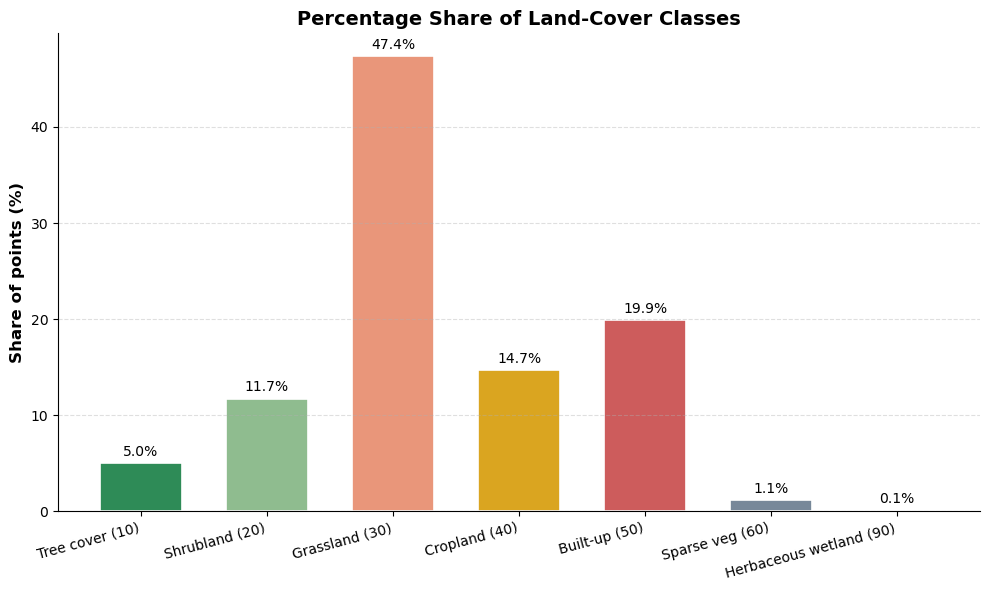

In [19]:

#1. Get the value counts sorted by index so they align with your land cover codes

land_cover_names = {
    10: "Tree cover (10)",
    20: "Shrubland (20)",
    30: "Grassland (30)",
    40: "Cropland (40)",
    50: "Built-up (50)",
    60: "Sparse veg (60)",
    90: "Herbaceous wetland (90)",
}

land_cover_share = df["land_cover"].value_counts(normalize=True).sort_index() * 100
labels = [land_cover_names[code] for code in land_cover_share.index]
values = land_cover_share.values

# 2. Define custom colors (mapped to codes so colors stay consistent even if a class is missing)
color_map = {
    10: "#2E8B57",  # Sea Green
    20: "#8FBC8F",  # Dark Sea Green
    30: "#E9967A",  # Dark Salmon
    40: "#DAA520",  # Goldenrod
    50: "#CD5C5C",  # Indian Red
    60: "#778899",  # Light Slate Gray
    90: "#4682B4",  # Steel Blue
}
bar_colors = [color_map[code] for code in land_cover_share.index]

# 3. Create the figure and plot
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    labels,
    values,
    color=bar_colors,
    edgecolor="white",
    linewidth=1.2,
    width=0.65,
)

# 4. Styling the graph
ax.set_ylabel("Share of points (%)", fontsize=12, fontweight="bold")
ax.set_title("Percentage Share of Land-Cover Classes", fontsize=14, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)

# Add percentage labels on top of the bars (1 decimal place)
ax.bar_label(bars, padding=3, fmt="%.1f%%")

plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


#### 2.4.7 Preliminary Flood Occurrence by Land-Cover Class

This analysis examines the proportion of sampled points labelled as flooded within each land-cover category.

The mean of the binary **flooded** variable is calculated for each land-cover class and multiplied by 100 to express the result as a percentage.

This helps investigate whether flood occurrence differs across land-cover categories.

The results provide an initial understanding of how land-cover characteristics may be associated with flood susceptibility in the study area.

**Note:** These percentages describe the available labelled samples. They do not establish that a particular land-cover class causes flooding.


In [20]:
#  Flood rate by land-cover class
print("Flood rate (%) by land-cover code:")
display((df.groupby("land_cover")["flooded"].mean() * 100).round(2))

Flood rate (%) by land-cover code:


land_cover
10    61.64
20    64.70
30    58.81
40    58.25
50    13.13
60    30.26
90    86.36
Name: flooded, dtype: float64

#### 2.4.8 Multivariate Analysis

In [21]:
target_col = "flooded"
selected_water_feature = "dist_river"

In [22]:
# 1. Spearman Correlation Matrix for Terrain & Water-Distance Features
corr_matrix = df[numeric_cols].corr(method='spearman')
display("Spearman Correlation Matrix (Checking Feature Overlap):")
display(corr_matrix.round(3))

# 2. Multi-level Grouping: Land Cover & Target vs. Key Water Distances/Elevation
water_cols = [c for c in numeric_cols if any(k in c.lower() for k in ['dist', 'elevation', 'slope'])]
if 'land_cover' in df.columns and water_cols:
    multi_group = df.groupby(['land_cover', target_col])[water_cols].median()
    display("Multi-Level Median Summary (Land Cover & Target vs. Water/Elevation Metrics):")
    display(multi_group)

'Spearman Correlation Matrix (Checking Feature Overlap):'

,point_id,lon,lat,flooded,elevation,slope,local_relief_100,local_relief_500,concavity,builtup_100,builtup_500,dist_river,dist_stream,dist_drain
point_id,1.000,-0.002,-0.003,-0.006,0.003,0.001,-0.007,-0.003,-0.000,-0.007,-0.008,0.001,0.000,-0.003
lon,-0.002,1.000,0.072,0.390,-0.912,-0.381,0.031,-0.011,-0.017,-0.545,-0.599,0.258,0.240,0.949
lat,-0.003,0.072,1.000,0.103,-0.294,-0.104,-0.038,-0.030,0.044,-0.214,-0.225,-0.085,-0.112,0.237
flooded,-0.006,0.390,0.103,1.000,-0.490,-0.329,-0.178,-0.376,0.203,-0.459,-0.438,-0.137,-0.150,0.347
elevation,0.003,-0.912,-0.294,-0.490,1.000,0.339,0.039,0.148,-0.056,0.602,0.644,-0.021,0.003,-0.904
slope,0.001,-0.381,-0.104,-0.329,0.339,1.000,-0.065,-0.135,0.048,0.447,0.501,-0.379,-0.381,-0.318
local_relief_100,-0.007,0.031,-0.038,-0.178,0.039,-0.065,1.000,0.593,-0.840,-0.023,-0.081,0.165,0.166,0.007
local_relief_500,-0.003,-0.011,-0.030,-0.376,0.148,-0.135,0.593,1.000,-0.588,0.087,-0.033,0.367,0.367,-0.027
concavity,-0.000,-0.017,0.044,0.203,-0.056,0.048,-0.840,-0.588,1.000,-0.003,0.058,-0.176,-0.178,0.002
builtup_100,-0.007,-0.545,-0.214,-0.459,0.602,0.447,-0.023,0.087,-0.003,1.000,0.873,-0.036,-0.031,-0.484


'Multi-Level Median Summary (Land Cover & Target vs. Water/Elevation Metrics):'

elevation     slope   dist_river  dist_stream  \
land_cover flooded                                                    
10         0        1571.760498  2.931126   528.065631   528.065631   
           1        1495.351562  2.106729    17.667931    17.667931   
20         0        1520.066162  1.574159   503.838826   512.850606   
           1        1491.990906  0.835066    62.010210    62.010210   
30         0        1497.536865  0.666373   817.247469   902.666229   
           1        1487.024658  0.377855   876.605303   876.605303   
40         0        1495.503540  0.810361   791.626622   792.850362   
           1        1483.666443  0.562219   211.738170   211.738170   
50         0        1570.799316  1.689632   527.439248   559.323832   
           1        1509.450989  1.157249   170.720527   170.720527   
60         0        1535.873535  1.715571   438.803409   503.596618   
           1        1491.420044  1.560501   169.266338   169.266338   
90         0        1513.645508  0.558230  2082.449689  2082.449689   
           1        1495.166748  0.339460   358.089461   358.089461   

                      dist_drain  
land_cover flooded                
10         0         2770.915490  
           1         6675.445223  
20         0         4661.182562  
           1         6853.177951  
30         0         8371.039699  
           1        11367.266809  
40         0         9980.199464  
           1        10155.566929  
50         0         2917.340492  
           1         4502.712853  
60         0         3134.609034  
           1         8890.927035  
90         0         6486.720897  
           1         6619.091100

#### Key Insights: Multivariate Analysis

* **Severe Multicollinearity:** `dist_river` and `dist_stream` are nearly identical
* **Spatial & Elevation Gradients:** `elevation` strongly correlates with `lon` ($r = -0.912$) and `dist_drain` ($r = -0.904$), showing that lower-lying eastern areas sit farthest from formal drainage and have higher flood susceptibility.
* **Land-Cover & Terrain Interaction:** Across land-cover classes and spatial blocks, flooded zones consistently cluster at lower elevations (around **1,495 m**) with flatter slopes (< **0.7°**), whereas higher elevations (> **1,630 m**) and steeper slopes (> **2.1°**) remain dry.

#### 2.4.9 Investigating the Water-Distance Features

In [23]:
distance_columns = ["dist_river", "dist_stream", "dist_drain"]
display(df[distance_columns].describe().T)

print(
    "Are dist_river and dist_stream identical for every row?",
    df["dist_river"].equals(df["dist_stream"])
)

print(
    "Correlation between dist_river and dist_stream:",
    df[["dist_river", "dist_stream"]].corr().iloc[0, 1].round(4)
)

,count,mean,std,min,25%,50%,75%,max
dist_river,19878.0,924.865255,981.791447,0.006882,161.863981,541.486468,1379.265397,3960.530420
dist_stream,19878.0,939.409319,981.149807,0.006882,166.184464,568.156431,1420.359440,3960.530420
dist_drain,19878.0,8124.809578,4816.577833,3.766930,3687.280848,7962.328653,12443.090507,18670.392919


Are dist_river and dist_stream identical for every row? False
Correlation between dist_river and dist_stream: 0.9918


In [24]:
# Compare water-distance features to justify feature selection in Section 3
water_cols = ['dist_river', 'dist_stream', 'dist_drain']
display(df[water_cols].corr(method='spearman').round(3))

# Check individual correlation with the target 'flooded'
display(df[water_cols + ['flooded']].corr(method='spearman')['flooded'].round(3))

,dist_river,dist_stream,dist_drain
dist_river,1.000,0.986,0.223
dist_stream,0.986,1.000,0.193
dist_drain,0.223,0.193,1.000


dist_river    -0.137
dist_stream   -0.150
dist_drain     0.347
flooded        1.000
Name: flooded, dtype: float64

In [25]:
display(df[["dist_river", "dist_stream", "dist_drain"]].describe())
print("River and stream distances are identical:", df["dist_river"].equals(df["dist_stream"]))

,dist_river,dist_stream,dist_drain
count,19878.000000,19878.000000,19878.000000
mean,924.865255,939.409319,8124.809578
std,981.791447,981.149807,4816.577833
min,0.006882,0.006882,3.766930
25%,161.863981,166.184464,3687.280848
50%,541.486468,568.156431,7962.328653
75%,1379.265397,1420.359440,12443.090507
max,3960.530420,3960.530420,18670.392919


River and stream distances are identical: False



#### 2.4.10 Examining Spatial Block Structure

The dataset is examined to understand how sampled geographic points are distributed across spatial blocks.

The analysis identifies:

- The total number of unique spatial blocks.
- The distribution of observations within these blocks.
- Whether the number of sampled points differs considerably between blocks.

Spatial blocks are important because nearby geographic observations may share similar environmental characteristics.

During model evaluation, using spatial blocks can help reduce the risk of overly optimistic results caused by training and testing on geographically close observations.

The **block_id** variable will therefore be retained as metadata for spatially informed data splitting and evaluation, rather than used as a model predictor.



In [26]:
# 4. Check spatial block structure
print("Number of unique spatial blocks:", df["block_id"].nunique())
print("Points per block summary:")
display(df["block_id"].value_counts().describe())

Number of unique spatial blocks: 525
Points per block summary:


count    525.000000
mean      37.862857
std       35.504492
min        1.000000
25%       20.000000
50%       27.000000
75%       40.000000
max      219.000000
Name: count, dtype: float64

In [27]:
# Check sample counts and flood rate (%) per spatial block
block_summary = df.groupby('block_id')['flooded'].agg(
    total_points='count',
    flooded_count='sum',
    flood_rate_pct=lambda x: round(x.mean() * 100, 2)
)
display(block_summary)

,total_points,flooded_count,flood_rate_pct
block_id,,,
259_9853,5,0,0.00
259_9854,8,0,0.00
259_9855,7,0,0.00
259_9856,10,0,0.00
259_9857,11,0,0.00
...,...,...,...
288_9867,33,26,78.79
288_9868,19,10,52.63
288_9869,55,49,89.09


**Key Insights: Spatial Clustering & Water-Distance Redundancy**

* **Spatial Clustering (**block_id**):** Across **525 spatial blocks** (1–219 points/block; median: **27**), flooding is heavily localized rather than uniform-ranging from **0.00%** in dry blocks ( 259_9853 –259_9857) to **89.09%** in high-risk zones (288_9869). 


### 2.5 Initial Visualisations

The tables in Section 2.4 summarise the dataset numerically. This section presents the same relationships visually so that patterns, interactions and spatial clusters are easier to see and communicate.

The visualisations are organised from general to spatial:

1. **Correlation heatmaps:** How the features relate to each other and to `flooded`.
2. **Feature distributions by flood class:** How each feature differs between flooded and non-flooded points.
3. **Flood-rate heatmaps:** How flood occurrence changes when two features are considered together.
4. **Static spatial maps:** Where flooded points, high flood rates and low-lying terrain are located.
5. **Spatial-block hotspots:** Which spatial blocks have consistently high flood rates.
6. **Interactive map:** A zoomable map of the flood points over a Nairobi basemap.

**Note:** These charts describe the labelled sample points. They show associations in the available data and do not establish causes of flooding.

#### 2.5.1 Visualisation Setup

A consistent visual style is defined once and reused by every chart in this section.

- **Class colours:** Blue represents *not flooded* (0) and orange represents *flooded* (1) in every chart, so the two classes are always recognisable.
- **Diverging colour scale:** Used for correlations and flood rates. Blue indicates negative correlation or low flood rate, grey indicates no correlation or a 50% flood rate, and red indicates positive correlation or high flood rate.
- **Readable labels:** Raw column names are mapped to descriptive labels for chart axes.
- **Land-cover names:** The land-cover codes are mapped to the same class names used in Section 2.4.

In [28]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Consistent class colours: 0 = not flooded (blue), 1 = flooded (orange)
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}
CLASS_LABELS = {0: "Not flooded (0)", 1: "Flooded (1)"}

# Diverging scale: blue (low / negative) -> grey (neutral) -> red (high / positive)
DIVERGING_CMAP = LinearSegmentedColormap.from_list(
    "flood_diverging", ["#1c5cab", "#86b6ef", "#f0efec", "#f19a8f", "#c0302f"]
)
# Sequential scale for magnitudes such as elevation
SEQUENTIAL_CMAP = LinearSegmentedColormap.from_list(
    "flood_sequential", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"]
)

FEATURE_LABELS = {
    "elevation": "Elevation (m)",
    "slope": "Slope",
    "local_relief_100": "Local relief (100)",
    "local_relief_500": "Local relief (500)",
    "concavity": "Concavity",
    "builtup_100": "Built-up (100)",
    "builtup_500": "Built-up (500)",
    "dist_river": "Distance to river (m)",
    "flooded": "Flooded",
}
viz_features = [c for c in FEATURE_LABELS if c != "flooded"]

LC_NAMES = {10: "Tree cover", 20: "Shrubland", 30: "Grassland", 40: "Cropland",
            50: "Built-up", 60: "Sparse veg", 90: "Wetland"}

viz_df = df.copy()
viz_df["land_cover_name"] = viz_df["land_cover"].map(LC_NAMES)
viz_df["flood_label"] = viz_df["flooded"].map(CLASS_LABELS)

#### 2.5.2 Correlation Heatmap of Numerical Features

The correlation matrix from Section 2.4.4 is shown as a heatmap so that strong relationships stand out by colour rather than having to be read from a table.

**Spearman rank correlation** is used instead of Pearson correlation because several features are heavily skewed (Section 2.4.3). Spearman measures whether two variables increase or decrease together, without assuming a straight-line relationship, and is less sensitive to outliers.

How to read the heatmap:

- **Red cells:** The two variables tend to increase together (positive correlation).
- **Blue cells:** One variable tends to decrease as the other increases (negative correlation).
- **Grey cells:** Little or no monotonic relationship.
- Only the lower triangle is shown because the matrix is symmetric.

The bottom row (**Flooded**) shows how each feature is associated with the target. Strong correlations between two *predictors* indicate redundancy that should be considered during feature selection.

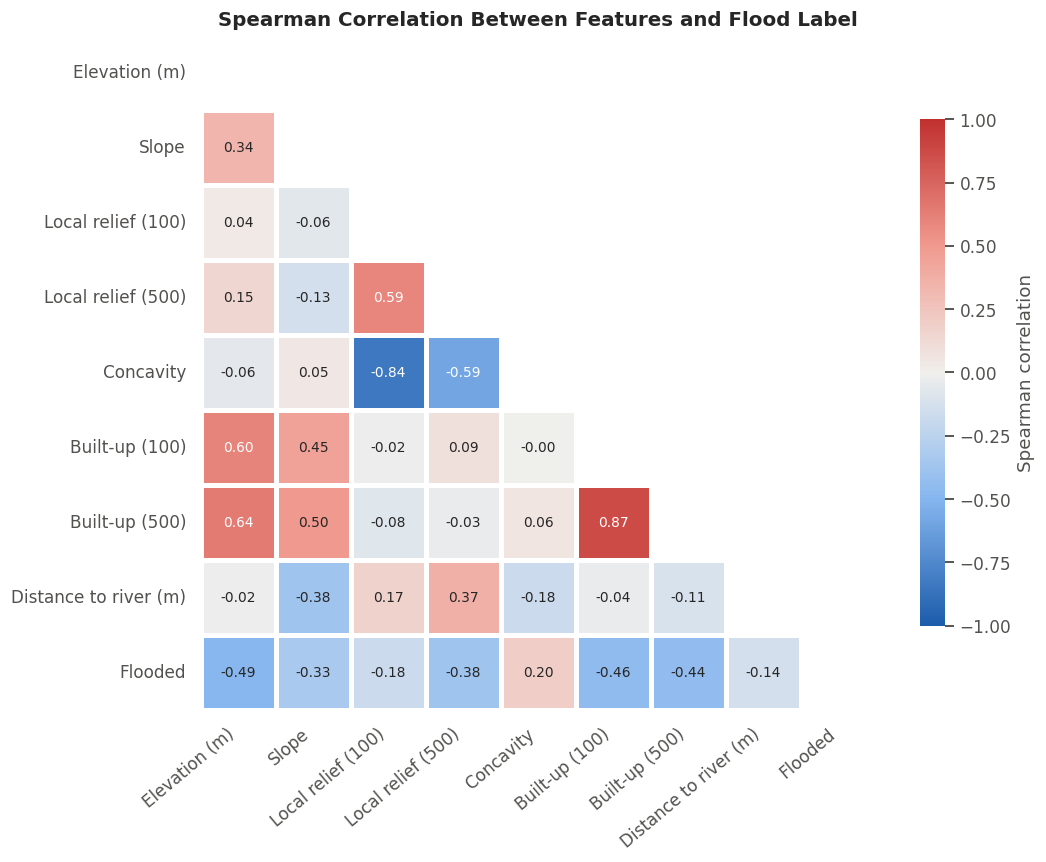

In [ ]:
spearman_corr = viz_df[viz_features + ["flooded"]].corr(method="spearman")
spearman_corr = spearman_corr.rename(index=FEATURE_LABELS, columns=FEATURE_LABELS)

# Hide the upper triangle (and diagonal) because the matrix is symmetric
upper_mask = np.triu(np.ones_like(spearman_corr, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    spearman_corr,
    mask=upper_mask,
    cmap=DIVERGING_CMAP,
    vmin=-1, vmax=1, center=0,
    annot=True, fmt=".2f", annot_kws={"size": 9},
    linewidths=2, linecolor="white",
    square=True,
    cbar_kws={"label": "Spearman correlation", "shrink": 0.75},
    ax=ax,
)
ax.set_title("Spearman Correlation Between Features and Flood Label")
ax.tick_params(axis="x", rotation=40)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
plt.show()
# plt.savefig("spearman_correlation_heatmap.png", dpi=300, bbox_inches="tight")

#### 2.5.3 Ranking Features by Association with Flooding

The heatmap shows all pairwise relationships. This chart isolates the bottom row, the correlation of each feature with **flooded**, and sorts it by strength.

- **Bars to the left (blue):** Higher values of the feature are associated with *fewer* flooded points.
- **Bars to the right (red):** Higher values of the feature are associated with *more* flooded points.
- **Longer bars:** Stronger association.

This ranking gives a first indication of which predictors may be most informative for the model. Final feature importance will be determined during modelling.

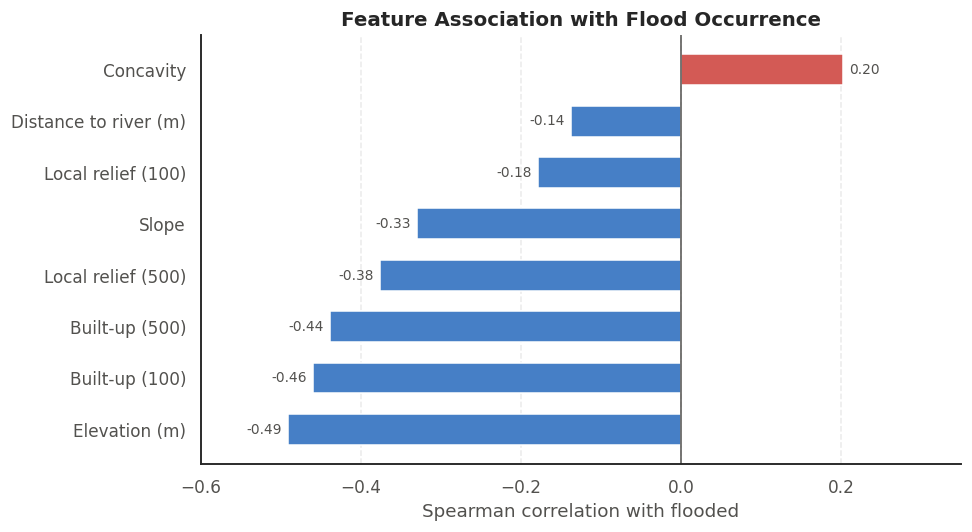

In [ ]:
target_corr = (
    viz_df[viz_features + ["flooded"]]
    .corr(method="spearman")["flooded"]
    .drop("flooded")
    .sort_values()
)

bar_colors = [DIVERGING_CMAP(0.1) if v < 0 else DIVERGING_CMAP(0.9) for v in target_corr]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh([FEATURE_LABELS[c] for c in target_corr.index], target_corr.values,
               color=bar_colors, height=0.6)
ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=9, color="#52514e")
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_xlim(-0.6, 0.35)
ax.set_xlabel("Spearman correlation with flooded")
ax.set_title("Feature Association with Flood Occurrence")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
# plt.show()
# plt.savefig("feature_correlation_with_flooded.png")

#### Key Insights: Correlation Heatmaps

* **Strongest signals are terrain and urban density:** `elevation` (**-0.49**), `builtup_100` (**-0.46**), `builtup_500` (**-0.44**), `local_relief_500` (**-0.38**) and `slope` (**-0.33**) have the strongest negative associations with flooding. Flooded points tend to be lower, flatter, sit in local depressions and have less built-up surroundings.
* **Concavity is the only clear positive association** (**+0.20**). Concave (bowl-shaped) terrain is where water collects.
* **Distance to river is weak on its own** (**-0.14**). Its relationship with flooding is not a simple straight line, so it is explored further in the flood-rate heatmap in Section 2.5.5.
* **Redundancy between predictors:** `builtup_100` and `builtup_500` are highly correlated (**0.87**), and `local_relief_100` is almost the mirror of `concavity` (Pearson **-0.95**, Section 2.4.4). Built-up density also rises with elevation (**~0.6**). These overlaps should be considered when interpreting feature importance, especially for linear models.

#### 2.5.4 Feature Distributions by Flood Class

Correlations summarise each relationship as a single number. Distribution plots show the full shape of each feature for flooded and non-flooded points, making it possible to see *where* the two classes overlap and where they separate.

For each numerical feature, two density curves are overlaid:

- **Blue curve:** Distribution of the feature for non-flooded points.
- **Orange curve:** Distribution of the feature for flooded points.
- **Dashed lines:** Median value for each class.

Where the curves are clearly separated, the feature distinguishes the classes well. Where they overlap heavily, the feature is less useful on its own.

**Note:** Because several features are highly skewed (Section 2.4.3), the x-axis of each plot is limited to the 1st–99th percentile range so that the main body of each distribution is visible. The extreme values are retained in the dataset.

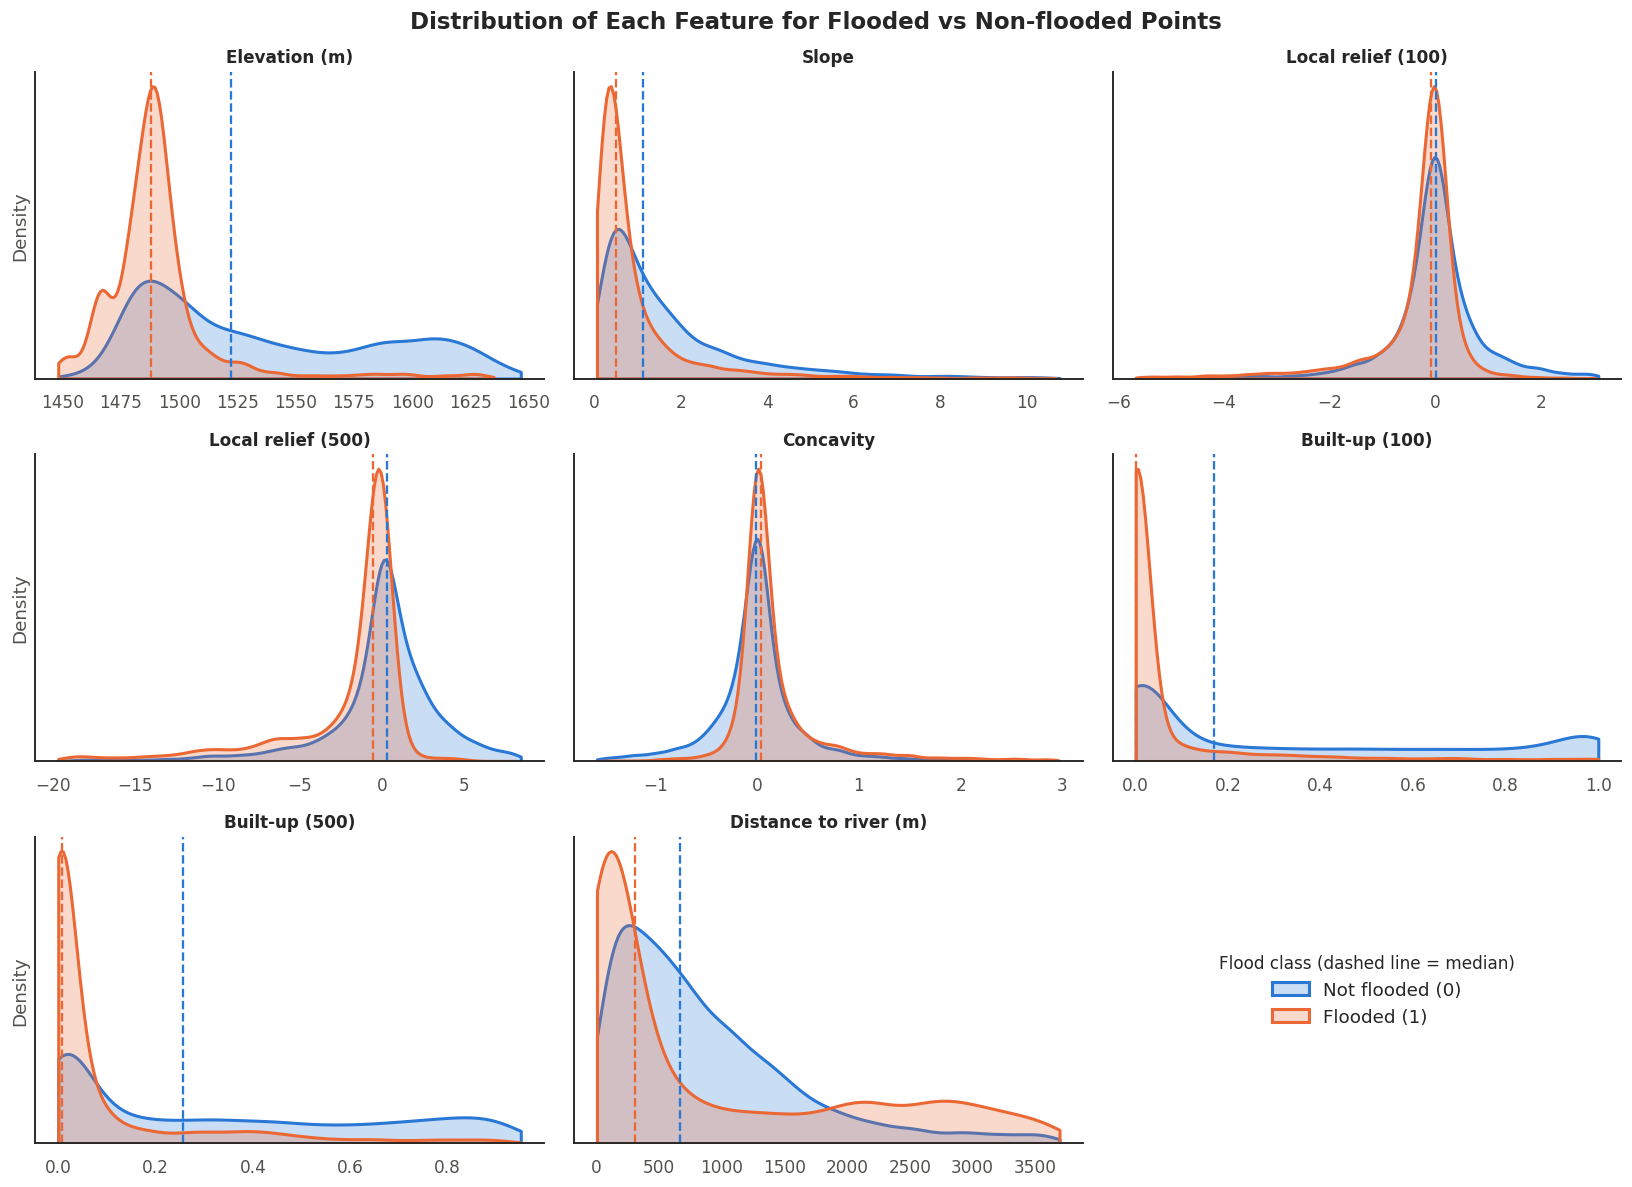

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
axes = axes.ravel()

for ax, col in zip(axes, viz_features):
    low, high = viz_df[col].quantile([0.01, 0.99])
    clipped = viz_df[viz_df[col].between(low, high)]

    for cls in (0, 1):
        values = clipped.loc[clipped["flooded"] == cls, col]
        sns.kdeplot(values, ax=ax, color=CLASS_COLORS[cls], fill=True, alpha=0.25,
                    linewidth=2, label=CLASS_LABELS[cls], cut=0, warn_singular=False)
        ax.axvline(viz_df.loc[viz_df["flooded"] == cls, col].median(),
                   color=CLASS_COLORS[cls], linestyle="--", linewidth=1.5)

    ax.set_title(FEATURE_LABELS[col], fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("Density" if ax in axes[::3] else "")
    ax.set_yticks([])

# The 9th panel holds the shared legend
axes[-1].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[-1].legend(handles, labels, loc="center", fontsize=12, frameon=False,
                title="Flood class (dashed line = median)", title_fontsize=11)

fig.suptitle("Distribution of Each Feature for Flooded vs Non-flooded Points",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()
# plt.savefig("feature_distribution_kde.png")

#### Key Insights: Feature Distributions

* **Elevation separates the classes most clearly.** Flooded points are concentrated in a narrow, low band around **1,480–1,500 m**, while non-flooded points extend up to about **1,670 m**. Above roughly **1,550 m** almost all points are non-flooded.
* **Built-up density shows a sharp contrast.** Most flooded points have **near-zero** built-up density, while non-flooded points have a long spread towards highly built-up surroundings.
* **Slope and local relief:** Flooded points are concentrated on very gentle slopes and at negative local relief (lower than their surroundings), consistent with water collecting in low, flat ground.
* **Distance to river is bimodal for flooded points.** Most flooded points cluster close to rivers (median about **310 m** vs **670 m**), but there is a second group of flooded points **2,000–3,500 m** from the nearest mapped river. These distant flooded points are likely low-lying areas that flood from surface water rather than river overflow. This second group explains the weak overall correlation despite the clear difference in medians (see Section 2.5.6).
* **Concavity and local_relief_100** overlap heavily around zero. Their differences are concentrated in the tails rather than the centre of the distribution.

#### 2.5.5 Flood-Rate Heatmap: Land Cover × Elevation Band

Section 2.4.7 showed that flood rates differ by land-cover class, and the plots above show that elevation is the strongest single feature. This heatmap combines the two to check whether the land-cover pattern holds after accounting for elevation.

- Elevation is divided into **six bands with roughly equal numbers of points** (quantile bins), so each column is based on a similar sample size.
- Each cell shows the **percentage of points that are flooded** for that land-cover class and elevation band.
- **Red** cells have a high flood rate, **blue** cells a low flood rate, and **grey** cells sit near the overall rate of 50%.
- The small number under each percentage is the **number of points** in the cell. Cells with fewer than **30 points** are left blank because their flood rates are unreliable.

This helps identify interactions, where the effect of one feature depends on the value of another.

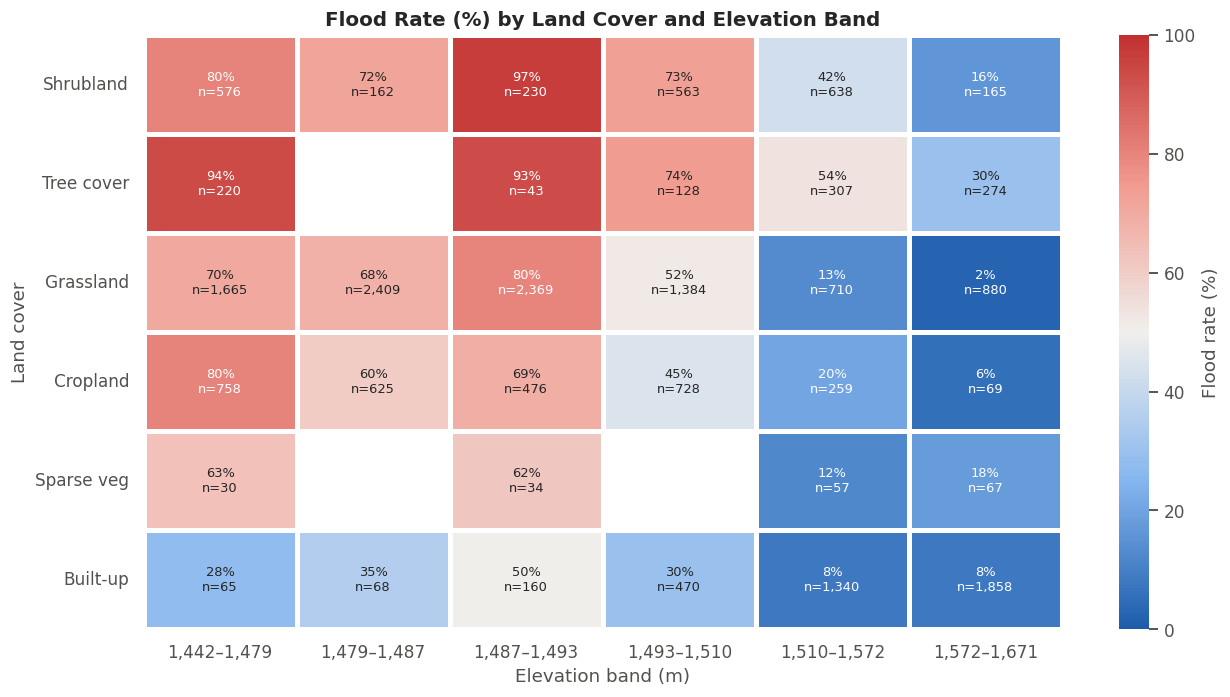

In [ ]:
MIN_CELL_POINTS = 30

def flood_rate_heatmap(data, row_col, col_col, title, row_label, col_label, ax):
    # Plot an annotated flood-rate heatmap for two binned / categorical variables
    rate = pd.crosstab(data[row_col], data[col_col], values=data["flooded"],
                       aggfunc="mean").mul(100)
    counts = pd.crosstab(data[row_col], data[col_col])
    rate = rate.reindex(index=counts.index, columns=counts.columns)
    rate = rate.where(counts >= MIN_CELL_POINTS)
    # Drop rows where every cell is below the threshold (nothing reliable to show)
    rate = rate.dropna(how="all")
    counts = counts.loc[rate.index]

    labels = rate.copy().astype(object)
    for r in rate.index:
        for c in rate.columns:
            labels.loc[r, c] = "" if pd.isna(rate.loc[r, c]) else f"{rate.loc[r, c]:.0f}%\nn={counts.loc[r, c]:,}"

    sns.heatmap(rate, annot=labels.values, fmt="", annot_kws={"size": 8.5},
                cmap=DIVERGING_CMAP, vmin=0, vmax=100, center=50,
                linewidths=2, linecolor="white",
                cbar_kws={"label": "Flood rate (%)"}, ax=ax)
    ax.set_title(title)
    ax.set_ylabel(row_label)
    ax.set_xlabel(col_label)
    ax.tick_params(axis="y", rotation=0)
    return rate, counts

# Six equal-count elevation bands with readable labels
viz_df["elevation_band"] = pd.qcut(viz_df["elevation"], q=6, precision=0)
viz_df["elevation_band"] = viz_df["elevation_band"].cat.rename_categories(
    lambda iv: f"{iv.left:,.0f}–{iv.right:,.0f}"
)

# Order land-cover classes by overall flood rate (highest first)
lc_order = viz_df.groupby("land_cover_name")["flooded"].mean().sort_values(ascending=False).index
viz_df["land_cover_name"] = pd.Categorical(viz_df["land_cover_name"], categories=lc_order, ordered=True)

fig, ax = plt.subplots(figsize=(12, 6.5))
lc_elev_rate, lc_elev_counts = flood_rate_heatmap(
    viz_df, "land_cover_name", "elevation_band",
    "Flood Rate (%) by Land Cover and Elevation Band",
    "Land cover", "Elevation band (m)", ax,
)
plt.tight_layout()
plt.show()
# plt.savefig("flood_rate_by_landcover_elevation.png")

#### Key Insights: Land Cover × Elevation

* **Elevation dominates within every land-cover class.** For each class with enough points, the flood rate falls sharply from the lowest elevation band to the highest. For example, Tree cover drops from about **94%** to **30%**, and Grassland from about **70%** to **2%**.
* **Built-up land stays at or below about 50% in every elevation band**, and is only **28%** in the lowest band, where other classes flood 63–94% of the time. This suggests that low flood rates in built-up areas are not only because built-up land tends to be higher. It may also reflect drainage infrastructure or how flood points were recorded in urban areas.
* **Vegetated classes at low elevation are the highest-risk combination.** Tree cover, Shrubland and Cropland below about **1,480 m** have flood rates of **80% or more**.
* **Wetland is not shown** because it has only **22 points** in total, so no cell reaches the 30-point threshold. Its high flood rate (86%) in Section 2.4.5 should be treated with caution.

#### 2.5.6 Flood-Rate Heatmap: Distance to River × Elevation Band

The correlation between `dist_river` and `flooded` was weak (Section 2.5.3), even though flooded points have a much lower median distance to rivers. This heatmap investigates whether the effect of river proximity depends on elevation.

- **Rows:** Distance-to-river bands in metres, from closest (top) to farthest (bottom).
- **Columns:** The same six elevation bands used above.
- **Cells:** Flood rate (%) and number of points, using the same colour scale and 30-point threshold.

If river proximity matters more at some elevations than others, it will appear as a change in the colour pattern across rows that differs between columns.

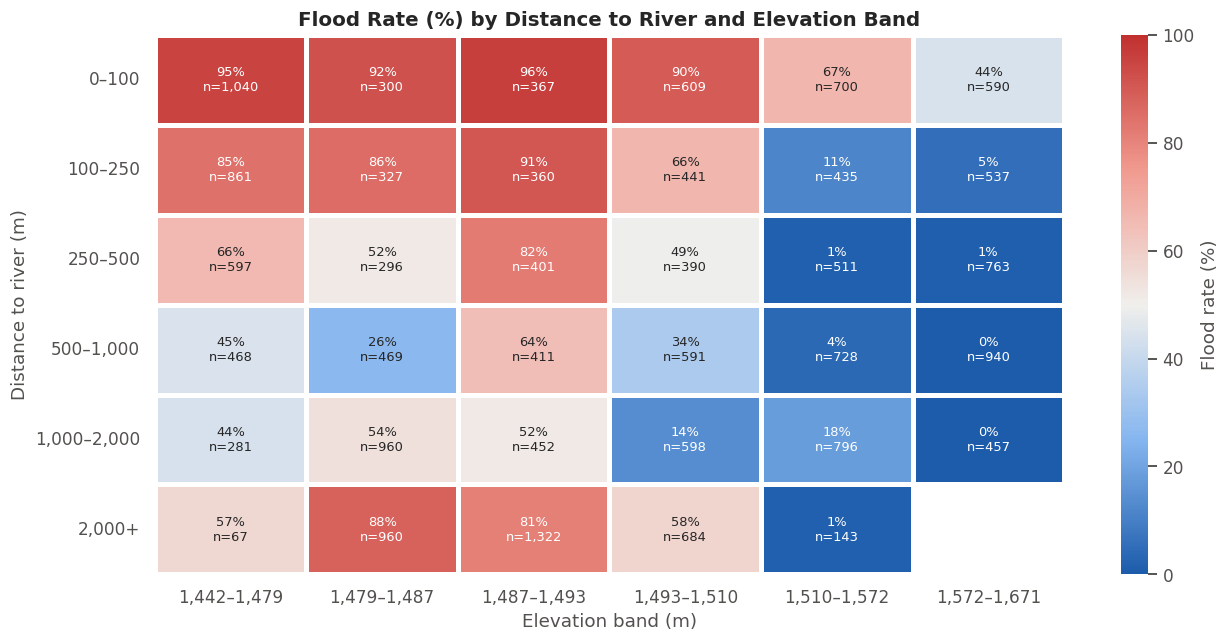

In [ ]:
river_bins = [0, 100, 250, 500, 1000, 2000, viz_df["dist_river"].max() + 1]
river_labels = ["0–100", "100–250", "250–500", "500–1,000", "1,000–2,000", "2,000+"]
viz_df["river_band"] = pd.cut(viz_df["dist_river"], bins=river_bins, labels=river_labels,
                              include_lowest=True)

fig, ax = plt.subplots(figsize=(12, 6))
river_elev_rate, river_elev_counts = flood_rate_heatmap(
    viz_df, "river_band", "elevation_band",
    "Flood Rate (%) by Distance to River and Elevation Band",
    "Distance to river (m)", "Elevation band (m)", ax,
)
plt.tight_layout()
plt.show()
# plt.savefig("flood_rate_by_river_distance_elevation.png")

#### Key Insights: Distance to River × Elevation

* **River proximity matters, but mainly together with elevation.** At the highest elevations, only points within **100 m** of a river have a meaningful flood rate (about **44%**). Beyond about **250 m** the flood rate there is close to **0%**.
* **Below about 1,510 m, flooding is common at every distance.** Points within 100 m of a river flood **90–96%** of the time. Points **more than 2 km** from a river in the 1,479–1,493 m bands also flood **81–88%** of the time, across more than 2,000 points. This is the second group of distant flooded points seen in Section 2.5.4. It suggests that some low-lying flat areas flood from surface water accumulation or unmapped watercourses rather than from the mapped rivers.
* **This interaction explains the weak overall correlation** of `dist_river`. Its effect depends strongly on elevation, which tree-based models can capture directly. For linear models, an interaction term may be worth testing.

#### 2.5.7 Spatial Distribution of Flood Labels

Because this is a geographic dataset, the sample points are plotted using their longitude (`lon`) and latitude (`lat`) coordinates to show *where* flooded and non-flooded points are located in the study area.

Three maps are shown side by side:

1. **Point map:** Every sample point, coloured by flood class. This shows the raw spatial pattern of the labels.
2. **Flood-rate hexagon map:** The study area is divided into small hexagonal cells, and each cell is coloured by the percentage of its points that are flooded. This removes the overplotting of thousands of individual points and highlights flood hotspots.
3. **Elevation hexagon map:** The same hexagonal cells coloured by mean elevation, so that the flood pattern can be compared directly with the terrain.

**Note:** At Nairobi's latitude (about 1.2° south), one degree of longitude and one degree of latitude are nearly the same distance on the ground, so the maps use an equal aspect ratio and are not visibly distorted.

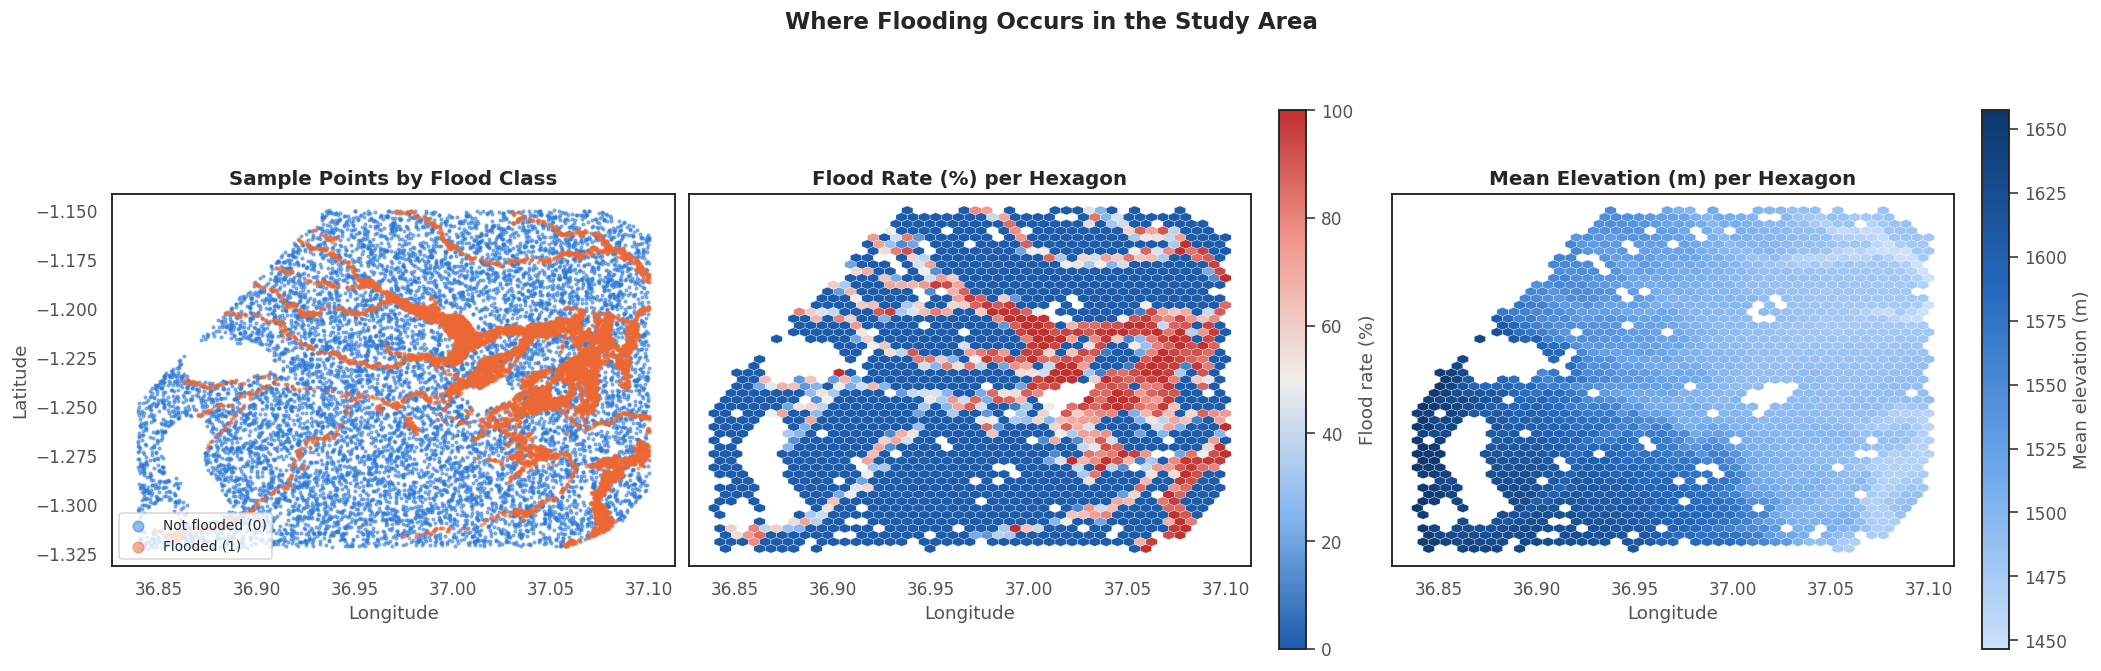

In [ ]:
HEX_GRID = 45  # number of hexagons across the study area

fig, axes = plt.subplots(1, 3, figsize=(19, 6.5), sharex=True, sharey=True, layout="constrained")

# 1. Point map: draw non-flooded first so flooded points sit on top
ax = axes[0]
for cls in (0, 1):
    pts = viz_df[viz_df["flooded"] == cls]
    ax.scatter(pts["lon"], pts["lat"], s=3, alpha=0.5, color=CLASS_COLORS[cls],
               label=CLASS_LABELS[cls], rasterized=True)
ax.set_title("Sample Points by Flood Class")
ax.legend(loc="lower left", markerscale=4, frameon=True, fontsize=9)

# 2. Flood-rate hexagons (mean of the 0/1 label = flood rate)
ax = axes[1]
hb = ax.hexbin(viz_df["lon"], viz_df["lat"], C=viz_df["flooded"] * 100,
               reduce_C_function=np.mean, gridsize=HEX_GRID, mincnt=3,
               cmap=DIVERGING_CMAP, vmin=0, vmax=100, linewidths=0.2, edgecolors="white")
fig.colorbar(hb, ax=ax, label="Flood rate (%)", shrink=0.8)
ax.set_title("Flood Rate (%) per Hexagon")

# 3. Mean elevation hexagons
ax = axes[2]
hb = ax.hexbin(viz_df["lon"], viz_df["lat"], C=viz_df["elevation"],
               reduce_C_function=np.mean, gridsize=HEX_GRID, mincnt=3,
               cmap=SEQUENTIAL_CMAP, linewidths=0.2, edgecolors="white")
fig.colorbar(hb, ax=ax, label="Mean elevation (m)", shrink=0.8)
ax.set_title("Mean Elevation (m) per Hexagon")

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("Longitude")
    ax.spines[["top", "right"]].set_visible(True)
axes[0].set_ylabel("Latitude")

fig.suptitle("Where Flooding Occurs in the Study Area", fontsize=15, fontweight="bold")
plt.show()
# plt.savefig("flood_rate_and_elevation_hexmaps.png")

#### Key Insights: Spatial Distribution

* **Flooding is strongly clustered, not scattered.** Flooded points form continuous zones rather than being spread evenly across the study area. Neighbouring points tend to share the same label, which confirms the need for **spatial block-based train/test splitting** (Section 2.4.10) to avoid overly optimistic model evaluation.
* **A clear west–east gradient:** The flood rate rises from about **18%** in the westernmost fifth of the points to about **72%** in the easternmost fifth.
* **The flood map mirrors the elevation map.** The high-flood-rate hexagons in the centre and east match the lower-lying (lighter) terrain, while the higher western areas (darker) are largely non-flooded. This visually confirms the strong elevation–longitude relationship (Spearman **-0.91**) found in Section 2.4.8.
* **Flooded points form narrow corridors.** The point map shows thin lines of flooded points running across the whole study area, including the higher north and west, and widening into broad flood zones in the centre and east. Their shape suggests that they follow river valleys and low-lying drainage lines. In the higher areas, flooding is confined to these corridors.

#### 2.5.8 Identifying Flood Hotspots by Spatial Block

Section 2.4.10 showed that flood rates vary widely between the 525 spatial blocks. The `block_id` values (for example, `277_9866`) appear to be grid-cell indices, which suggests each block is a square cell of roughly 1 km. This should be confirmed against the dataset documentation.

This visualisation summarises flooding at the block level:

1. **Histogram of block flood rates:** Shows whether blocks tend to be mixed (around 50%) or mostly one class (near 0% or 100%).
2. **Block hotspot map:** Each block is drawn at the average location of its points. Colour shows the block's flood rate, and marker size shows how many points it contains.

Blocks with a high flood rate *and* many sample points are the most reliable candidate **flood hotspots**.

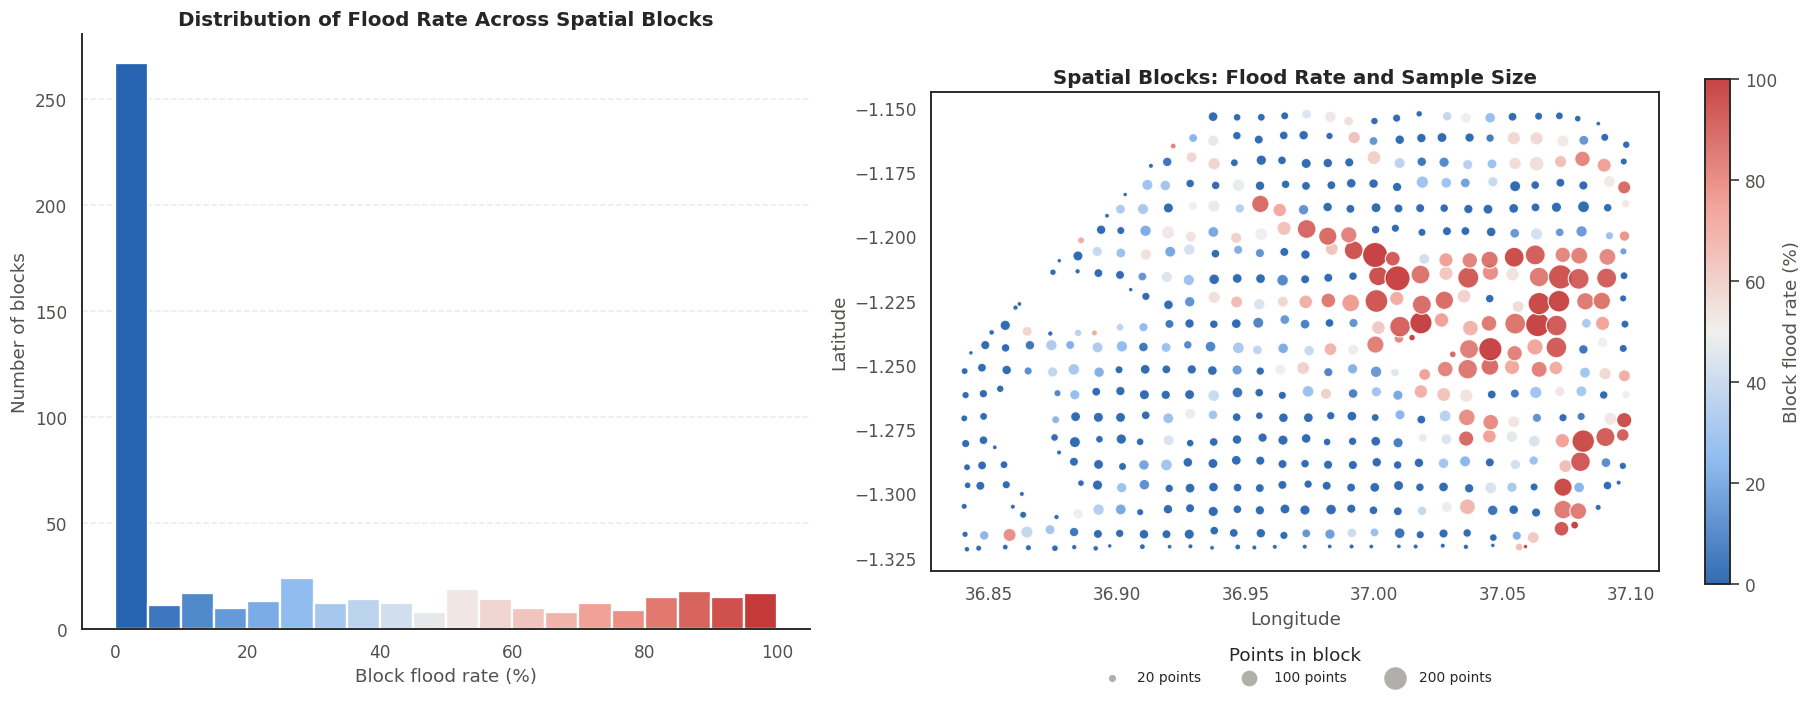

Blocks with 0% flooded:    256 of 525
Blocks with >= 80% flooded: 65 of 525

Top 10 hotspot blocks (at least 20 points), ranked by flood rate:


,block_id,total_points,flood_rate_pct,lon,lat,mean_elevation
0,277_9866,219,100.0,37.0004,-1.2072,1493.0
1,279_9863,170,100.0,37.0182,-1.2336,1489.0
2,278_9865,219,99.1,37.0091,-1.2163,1489.0
3,284_9863,204,99.0,37.0637,-1.2343,1486.0
4,282_9862,187,98.9,37.0452,-1.2439,1490.0
5,285_9864,161,98.8,37.0719,-1.2252,1483.0
6,284_9864,171,97.7,37.0642,-1.2261,1484.0
7,285_9856,113,97.3,37.0735,-1.2976,1468.0
8,286_9858,175,97.1,37.0813,-1.2796,1465.0
9,283_9866,134,97.0,37.0545,-1.2081,1477.0


In [ ]:
block_stats = viz_df.groupby("block_id").agg(
    total_points=("flooded", "size"),
    flood_rate_pct=("flooded", lambda s: s.mean() * 100),
    lon=("lon", "mean"),
    lat=("lat", "mean"),
    mean_elevation=("elevation", "mean"),
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1, 1.25]})

# 1. Histogram of block flood rates, coloured along the same diverging scale
ax = axes[0]
counts, edges, patches = ax.hist(block_stats["flood_rate_pct"], bins=20, range=(0, 100),
                                 edgecolor="white", linewidth=1.5)
for patch, left in zip(patches, edges[:-1]):
    patch.set_facecolor(DIVERGING_CMAP((left + 2.5) / 100))
ax.set_xlabel("Block flood rate (%)")
ax.set_ylabel("Number of blocks")
ax.set_title("Distribution of Flood Rate Across Spatial Blocks")
ax.grid(axis="y", linestyle="--", alpha=0.4)

# 2. Block hotspot map
ax = axes[1]
sc = ax.scatter(block_stats["lon"], block_stats["lat"],
                c=block_stats["flood_rate_pct"], cmap=DIVERGING_CMAP, vmin=0, vmax=100,
                s=block_stats["total_points"] * 1.2 + 8,
                edgecolors="white", linewidths=0.8, alpha=0.9)
fig.colorbar(sc, ax=ax, label="Block flood rate (%)", shrink=0.85)
for n in (20, 100, 200):
    ax.scatter([], [], s=n * 1.2 + 8, color="#b0afa9", edgecolors="white", label=f"{n} points")
ax.legend(title="Points in block", loc="upper center", bbox_to_anchor=(0.5, -0.13),
          ncol=3, frameon=False, fontsize=9, columnspacing=2.5)
ax.set_aspect("equal")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Spatial Blocks: Flood Rate and Sample Size")
ax.spines[["top", "right"]].set_visible(True)

plt.tight_layout()
plt.show()
plt.savefig("flood_hotspot_analysis.png")

print(f"Blocks with 0% flooded:    {(block_stats['flood_rate_pct'] == 0).sum()} of {len(block_stats)}")
print(f"Blocks with >= 80% flooded: {(block_stats['flood_rate_pct'] >= 80).sum()} of {len(block_stats)}")

print("\nTop 10 hotspot blocks (at least 20 points), ranked by flood rate:")
display(
    block_stats[block_stats["total_points"] >= 20]
    .sort_values(["flood_rate_pct", "total_points"], ascending=False)
    .head(10)
    .round({"flood_rate_pct": 1, "lon": 4, "lat": 4, "mean_elevation": 0})
    .reset_index(drop=True)
)

#### Key Insights: Spatial-Block Hotspots

* **Most blocks are almost entirely one class.** **256 of 525 blocks (49%)** contain no flooded points at all, and **65 blocks** have a flood rate of 80% or more. Relatively few blocks are mixed. Location alone is therefore highly predictive of the label, which is exactly why random train/test splits would overestimate model performance.
* **Hotspots are concentrated in the low-lying centre and east** of the study area, around longitude **37.00–37.08** and latitude **-1.20 to -1.30**. The top hotspot blocks contain **110–220 points each** with flood rates of **97–100%**, making them well-supported candidate hotspots.
* **Sampling intensity differs between blocks.** The largest, densest blocks are mostly the flooded hotspots, while many dry blocks contain fewer points. This reflects how the labelled points were sampled and should be kept in mind when interpreting the predicted susceptibility map.

#### 2.5.9 Interactive Flood Distribution Map

The static maps above show the overall pattern but do not show the streets, rivers and neighbourhoods underneath. An interactive map overlays the sample points on a real basemap of Nairobi so that the flood clusters can be related to familiar places.

The map is built with **Plotly** and contains three layers that can be switched on and off by clicking the legend:

- **Flood density heatmap:** A smoothed heatmap of the *flooded* points only. Brighter, warmer areas have a higher concentration of flooded points. This is the main view for identifying flood hotspots.
- **Flooded points (orange):** The individual flooded sample points.
- **Not flooded points (blue):** The individual non-flooded sample points (hidden by default to keep the map readable).

Hovering over a point shows its flood label, land cover, elevation, slope and distance to the nearest river.

The map is also saved as **flood_distribution_map.html** so it can be opened in a web browser and shared with stakeholders who do not use Jupyter.

**Note:** The basemap tiles are loaded from the internet, so an internet connection is required to see the background map. Plotly can be installed with `pip install plotly` if it is not already available.

In [ ]:
import plotly.graph_objects as go

flooded_pts = viz_df[viz_df["flooded"] == 1]
dry_pts = viz_df[viz_df["flooded"] == 0]

HOVER_TEMPLATE = (
    "<b>%{customdata[0]}</b><br>"
    "Land cover: %{customdata[1]}<br>"
    "Elevation: %{customdata[2]:,.0f} m<br>"
    "Slope: %{customdata[3]:.2f}<br>"
    "Distance to river: %{customdata[4]:,.0f} m<br>"
    "Block: %{customdata[5]}"
    "<extra></extra>"
)
hover_cols = ["flood_label", "land_cover_name", "elevation", "slope", "dist_river", "block_id"]

def point_layer(points, cls, visible=True):
    return go.Scattermap(
        lon=points["lon"].round(5), lat=points["lat"].round(5),
        mode="markers",
        marker=dict(size=5, color=CLASS_COLORS[cls], opacity=0.7),
        name=CLASS_LABELS[cls],
        customdata=points[hover_cols].values,
        hovertemplate=HOVER_TEMPLATE,
        visible=True if visible else "legendonly",
    )

flood_map = go.Figure()

# Layer 1: kernel-density heatmap of flooded points
flood_map.add_trace(go.Densitymap(
    lon=flooded_pts["lon"].round(5), lat=flooded_pts["lat"].round(5),
    radius=8, opacity=0.75,
    colorscale=[[0, "rgba(255,255,255,0)"], [0.2, "#fde0c5"], [0.45, "#f19a6b"],
                [0.7, "#e34948"], [1, "#8c1c1c"]],
    showscale=True,
    colorbar=dict(title="Flooded point<br>density", thickness=12, len=0.6),
    name="Flood density heatmap",
    showlegend=True,
    hoverinfo="skip",
))

# Layers 2 and 3: individual points
flood_map.add_trace(point_layer(flooded_pts, 1, visible=False))
flood_map.add_trace(point_layer(dry_pts, 0, visible=False))

flood_map.update_layout(
    title=dict(text="<b>Nairobi Flood Sample Points: Interactive Distribution Map</b>", x=0.01),
    map=dict(
        style="carto-positron",
        center=dict(lon=viz_df["lon"].mean(), lat=viz_df["lat"].mean()),
        zoom=11,
    ),
    height=650,
    margin=dict(l=0, r=0, t=50, b=0),
    legend=dict(title="Layers (click to toggle)", x=0.01, y=0.99,
                bgcolor="rgba(255,255,255,0.85)"),
)

flood_map.write_html("flood_distribution_map.html", include_plotlyjs="cdn")
print("Interactive map saved as flood_distribution_map.html")
flood_map.show()


Interactive map saved as flood_distribution_map.html


#### Key Insights: Interactive Map

* **The flood density heatmap highlights several distinct hotspots** in the central and eastern parts of the study area rather than one continuous flood zone.
* **Flooded points line up with river corridors.** Turning on the *Flooded points* layer and zooming in shows that many flooded points follow the courses of rivers and low-lying valleys. This is consistent with the strong flood rates within 100 m of rivers found in Section 2.5.6.
* **The western and south-western parts of the city**, which are higher and more built-up, contain very few flooded points.
* The interactive map is a **preview of the final deliverable**. The same approach can later be used to display the model's predicted flood-susceptibility scores instead of the observed labels.

#### 2.5.10 Summary of the Initial Visualisations

The visual exploration supports and extends the findings from Section 2.4:

| Finding | Evidence | Implication for modelling |
|---|---|---|
| Elevation is the strongest single predictor | Correlation ranking, distribution plots, elevation map | Retain as a core predictor |
| Built-up density and terrain shape (slope, relief, concavity) add information | Correlation ranking, distribution plots | Retain; be aware of overlap between `builtup_100` / `builtup_500` and `local_relief_100` / `concavity` |
| River proximity matters mainly in combination with elevation | Distance-to-river × elevation heatmap | Prefer models that capture interactions, such as tree-based models |
| Land-cover effects persist after controlling for elevation | Land-cover × elevation heatmap | Retain `land_cover` as a categorical predictor; treat Wetland results with caution because of its small sample |
| Flood labels are strongly spatially clustered | Point map, hexagon map, block histogram | Use **block-based spatial cross-validation** using `block_id` |
| Flood hotspots are in the low-lying centre and east | Hexagon map, block hotspot map, interactive map | Use these areas to sense-check the model's predicted susceptibility map |

## 3. DATA PREPARATION
The data preparation stage focuses on organising and validating the dataset before it is handed over for machine-learning development.

The main activities include:

- Confirming the selection of the water-distance feature.
- Validating the availability of required columns.
- Checking the target variable and point identifiers.
- Removing duplicate records.
- Separating predictors, target variables and metadata.
- Preparing a consistent dataset for downstream modelling.

The objective is to produce a clearly structured dataset that can be used by the modelling team while retaining the geographic information needed for spatial analysis and mapping.

### 3.1 Validate the Data Before Preparing the Shared Table

After preparing the dataset, final checks are performed to assess its structural consistency.

The checks examine:

- **Missing values:** Identifies whether any columns contain incomplete observations.
- **Duplicate records:** Confirms whether duplicate rows remain.
- **Flood labels:** Checks the distribution of the target variable after preparation.

These checks are important to ensure that the prepared dataset is suitable for the next stage of the project.

Any remaining missing values, unexpected target labels or duplicate records should be investigated before model development.

**Note:** This cell performs validation checks. It does not automatically remove missing values or correct invalid target labels.

In [ ]:
required_columns = ["point_id", "lon", "lat", "flooded", "elevation", "slope",
                   "local_relief_100", "local_relief_500", "concavity", "land_cover",
                   "builtup_100", "builtup_500", "dist_river", "dist_stream",
                   "dist_drain", "block_id"]

print("Missing required columns:", [col for col in required_columns if col not in df.columns])
print("Only 0 and 1 in target:", df["flooded"].isin([0, 1]).all())
print("Point IDs are unique:", df["point_id"].is_unique)

Missing required columns: []
Only 0 and 1 in target: True
Point IDs are unique: True


### 3.2 Creating the Shared Dataset

In [ ]:
prepared_df = df.drop_duplicates().copy()

# Keep only one water-distance feature and remove dist_drain.
if selected_water_feature == "dist_river":
    prepared_df = prepared_df.drop(columns=["dist_stream", "dist_drain"])
else:
    prepared_df = prepared_df.drop(columns=["dist_river", "dist_drain"])

numeric_features = ["elevation", "slope", "local_relief_100", "local_relief_500",
                    "concavity", "builtup_100", "builtup_500", selected_water_feature]
categorical_features = ["land_cover"]
feature_columns = numeric_features + categorical_features
metadata_columns = ["point_id", "lon", "lat", "block_id"]

display(prepared_df.head())
print("Prepared dataset shape:", prepared_df.shape)
print("Candidate predictors:", feature_columns)

,point_id,lon,lat,flooded,elevation,slope,local_relief_100,local_relief_500,concavity,land_cover,builtup_100,builtup_500,dist_river,block_id
0,1,37.054329,-1.299028,0,1497.815308,0.643400,0.784040,0.919611,-0.242782,40,0.009070,0.076953,343.582858,283_9856
1,2,37.051868,-1.297120,1,1491.494019,1.070903,-0.562037,-3.348700,0.486544,30,0.000000,0.098520,8.770712,283_9856
2,3,36.979077,-1.223612,1,1503.143555,0.114747,-0.132010,-1.802306,0.111572,30,0.034014,0.235663,93.445852,275_9864
3,4,37.086873,-1.232403,1,1486.456299,0.068787,-0.188992,-0.402524,0.026636,30,0.000000,0.003921,2807.757821,287_9863
4,5,37.068898,-1.188922,0,1480.674805,0.426800,-0.134649,0.193810,0.016965,30,0.000000,0.000000,1369.394675,285_9868


Prepared dataset shape: (19878, 14)
Candidate predictors: ['elevation', 'slope', 'local_relief_100', 'local_relief_500', 'concavity', 'builtup_100', 'builtup_500', 'dist_river', 'land_cover']


In [ ]:
# Final check on the share data set
print("Missing values:")
display(prepared_df.isnull().sum())
print("Duplicate rows:", prepared_df.duplicated().sum())
print("Flood labels:")
display(prepared_df["flooded"].value_counts())

Missing values:


point_id            0
lon                 0
lat                 0
flooded             0
elevation           0
slope               0
local_relief_100    0
local_relief_500    0
concavity           0
land_cover          0
builtup_100         0
builtup_500         0
dist_river          0
block_id            0
dtype: int64

Duplicate rows: 0
Flood labels:


flooded
1    9971
0    9907
Name: count, dtype: int64

### 3.3 Preparing the Three Handover Files

The data preparation stage produces three important files for the next stage of the capstone project.

**1. modelling_table.csv**

Contains the prepared dataset, including the selected candidate predictors, target variable (`flooded`) and required metadata (`point_id`, `lon`, `lat`, `block_id`).

The metadata is retained for mapping, identification and spatial data splitting. It should not automatically be treated as model input.

**2. feature_list.csv**

Documents all variables and their assigned roles in the project.

It identifies which features are candidate predictors, the target variable, metadata and excluded variables.

**3. data_dictionary.csv**

Provides descriptions and planned project uses for the original dataset columns.

It helps the team understand the meaning and intended purpose of each variable.



In [ ]:
# List each column and its role in the project.
feature_list = pd.DataFrame([
    ["elevation", "predictor", True],
    ["slope", "predictor", True],
    ["local_relief_100", "predictor", True],
    ["local_relief_500", "predictor", True],
    ["concavity", "predictor", True],
    ["land_cover", "predictor", True],
    ["builtup_100", "predictor", True],
    ["builtup_500", "predictor", True],
    [selected_water_feature, "predictor", True],
    ["flooded", "target", False],
    ["point_id", "metadata", False],
    ["lon", "metadata", False],
    ["lat", "metadata", False],
    ["block_id", "metadata", False],
    ["dist_drain", "excluded", False],
    ["dist_stream" if selected_water_feature == "dist_river" else "dist_river", "excluded", False]
], columns=["feature_name", "role", "included_in_modelling_inputs"])

feature_list["data_type"] = feature_list["feature_name"].map(df.dtypes.astype(str))
display(feature_list)

prepared_df.to_csv("modelling_table.csv", index=False)
feature_list.to_csv("feature_list.csv", index=False)
data_dictionary.to_csv("data_dictionary.csv", index=False)
print("The three project files have been saved.")

,feature_name,role,included_in_modelling_inputs,data_type
0,elevation,predictor,True,float64
1,slope,predictor,True,float64
2,local_relief_100,predictor,True,float64
3,local_relief_500,predictor,True,float64
4,concavity,predictor,True,float64
5,land_cover,predictor,True,int64
6,builtup_100,predictor,True,float64
7,builtup_500,predictor,True,float64
8,dist_river,predictor,True,float64
9,flooded,target,False,int64


The three project files have been saved.
